<a href="https://colab.research.google.com/github/kiplimoowen-cmyk/summatives/blob/main/Waste_management_summative.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
import os
import random
import json
import re
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [2]:
# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

# Your code here
import urllib.request
import zipfile

url = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"
zip_path = "/content/realwaste.zip"
extract_dir = "/content/realwaste_data"

#Download and extract RealWaste
if not os.path.exists(zip_path):
    print("Downloading RealWaste...")
    urllib.request.urlretrieve(url, zip_path)

if not os.path.exists(extract_dir):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)

print("Dataset is ready.")

Extracting dataset...
Dataset is ready.


In [3]:
# Locate the folder containing the waste categories
image_extensions = (".jpg", ".jpeg", ".png")
data_dir = None

for root, dirs, files in os.walk(extract_dir):
    category_dirs = [
        folder for folder in dirs
        if any(
            f.lower().endswith(image_extensions)
            for f in os.listdir(os.path.join(root, folder))
        )
    ]

    if len(category_dirs) >= 8:
        data_dir = pathlib.Path(root)
        class_names = sorted(category_dirs)
        break

if data_dir is None:
    raise FileNotFoundError(
        "Could not locate the category folders. Check the extracted files."
    )

print("Dataset directory:", data_dir)
print("Number of categories:", len(class_names))
print("Categories:", class_names)


Dataset directory: /content/realwaste_data/realwaste-main/RealWaste
Number of categories: 9
Categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


In [4]:
#count images in each category
category_counts = {}

for category in class_names:
    folder = data_dir / category
    category_counts[category] = sum(
        1 for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

print("Total images:", sum(category_counts.values()))

display(pd.DataFrame({
    "Category": list(category_counts.keys()),
    "Image Count": list(category_counts.values())
}))


Total images: 4752


,Category,Image Count
0,Cardboard,461
1,Food Organics,411
2,Glass,420
3,Metal,790
4,Miscellaneous Trash,495
5,Paper,500
6,Plastic,921
7,Textile Trash,318
8,Vegetation,436


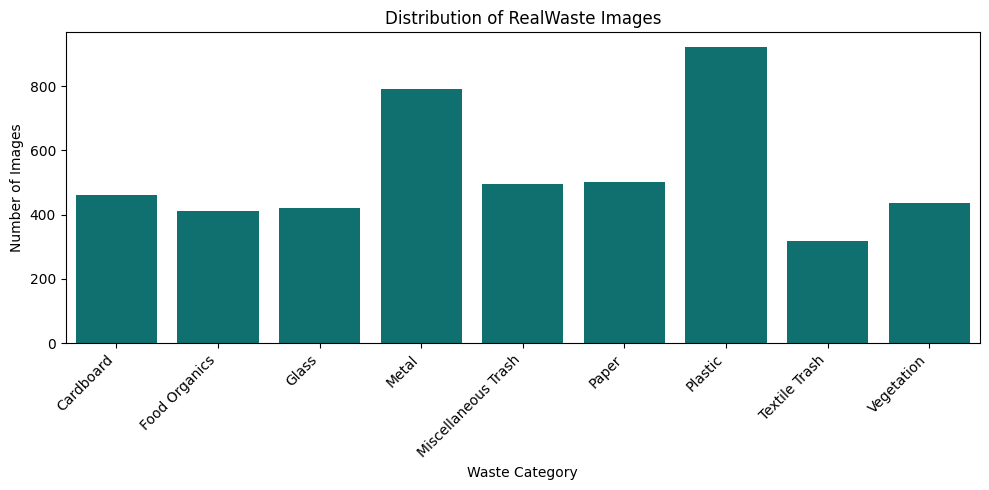

In [5]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x=list(category_counts.keys()),
    y=list(category_counts.values()),
    color='teal'
)
plt.title("Distribution of RealWaste Images")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The chart shows an uneven distribution of images across the nine waste categories in the RealWaste dataset. Plastic has the highest number of images at approximately 920, followed by metal with around 790. Textile trash has the fewest images at roughly 320, while the remaining categories contain approximately 410–500 images each

In [6]:
#chech image dimensions and color nodes
from PIL import Image

image_details = []

for category in class_names:
    files = [
        file for file in (data_dir / category).iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    for file in files[:20]:
        try:
            with Image.open(file) as img:
                image_details.append({
                    "Category": category,
                    "Width": img.width,
                    "Height": img.height,
                    "Color Mode": img.mode,
                    "Format": img.format
                })
        except Exception as error:
            print("Could not read:", file, error)

image_df = pd.DataFrame(image_details)

print("Images inspected:", len(image_df))
display(image_df.describe(include="all"))
print("\nColor modes:")
display(image_df["Color Mode"].value_counts())


Images inspected: 180


,Category,Width,Height,Color Mode,Format
count,180,180.0,180.0,180,180
unique,9,NaN,NaN,1,1
top,Cardboard,NaN,NaN,RGB,JPEG
freq,20,NaN,NaN,180,180
mean,NaN,524.0,524.0,NaN,NaN
std,NaN,0.0,0.0,NaN,NaN
min,NaN,524.0,524.0,NaN,NaN
25%,NaN,524.0,524.0,NaN,NaN
50%,NaN,524.0,524.0,NaN,NaN
75%,NaN,524.0,524.0,NaN,NaN



Color modes:


,count
Color Mode,
RGB,180


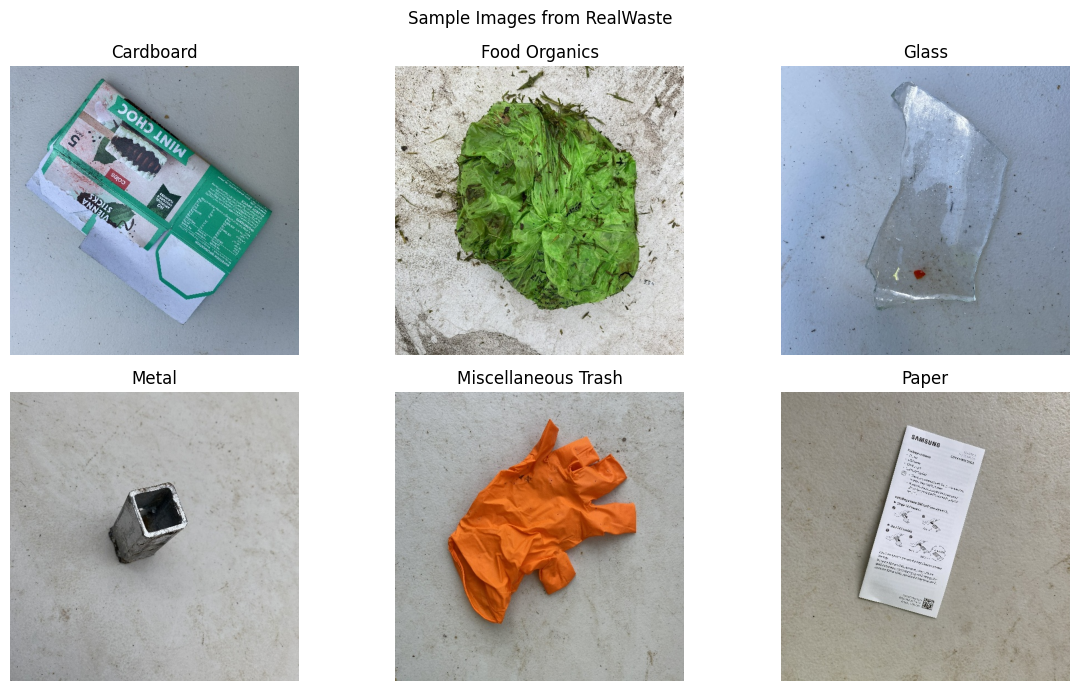

In [7]:
#view image sample from different categories
plt.figure(figsize=(12, 7))

for i, category in enumerate(class_names[:6]):
    files = [
        file for file in (data_dir / category).iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    if files:
        with Image.open(files[0]) as img:
            plt.subplot(2, 3, i + 1)
            plt.imshow(img.convert("RGB"))
            plt.title(category)
            plt.axis("off")

plt.suptitle("Sample Images from RealWaste")
plt.tight_layout()
plt.show()


### 1.2 Explore Text Datasets

In [8]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories

# Your code here
# Load and explore waste description data

descriptions_path = "/content/waste_descriptions.csv"

waste_df = pd.read_csv(descriptions_path)

print("Dataset shape:", waste_df.shape)
print("\nColumn names:")
print(waste_df.columns.tolist())

print("\nDataset information:")
waste_df.info()

print("\nFirst five rows:")
display(waste_df.head())

Dataset shape: (5000, 5)

Column names:
['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   description           5000 non-null   object
 1   category              5000 non-null   object
 2   disposal_instruction  5000 non-null   object
 3   common_confusion      2496 non-null   object
 4   material_composition  5000 non-null   object
dtypes: object(5)
memory usage: 195.4+ KB

First five rows:


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...


In [9]:
#Check data quality and category distribution
print("Missing values per column:")
display(waste_df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", waste_df.duplicated().sum())

print("\nRecords per category:")
display(waste_df["category"].value_counts().to_frame("Count"))

Missing values per column:


,Missing Values
description,0
category,0
disposal_instruction,0
common_confusion,2504
material_composition,0



Duplicate rows: 7

Records per category:


,Count
category,
Vegetation,600
Textile Trash,586
Cardboard,584
Miscellaneous Trash,578
Plastic,569
Glass,551
Food Organics,518
Metal,508
Paper,506


In [10]:
# Examine description length and vocabulary

text_column = "description"

waste_df["word_count"] = (
    waste_df[text_column]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("Description word-count summary:")
display(waste_df["word_count"].describe())

# Count unique words across the descriptions
all_words = (
    waste_df[text_column]
    .dropna()
    .astype(str)
    .str.lower()
    .str.findall(r"\b[a-z]+\b")
)

vocabulary = set(word for words in all_words for word in words)

print("Unique vocabulary size:", len(vocabulary))
print("Sample vocabulary:", sorted(vocabulary)[:30])

Description word-count summary:


,word_count
count,5000.000000
mean,4.854000
std,1.549956
min,1.000000
25%,4.000000
50%,5.000000
75%,6.000000
max,10.000000


Unique vocabulary size: 309
Sample vocabulary: ['a', 'aerosol', 'aluminum', 'apple', 'appliance', 'artisanal', 'attached', 'avocado', 'b', 'baby', 'bag', 'bags', 'bamboo', 'banana', 'band', 'bark', 'battery', 'bed', 'beer', 'belt', 'beverage', 'biodegradable', 'black', 'blue', 'bones', 'book', 'bottle', 'box', 'branches', 'brand']


The waste description dataset contains 5,000 records with 309 unique words. Each description averages about five words with lengths ranging from one to ten words. The vocabulary includes common waste-related items such as bottles, bags and boxes.

In [11]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language

# Your code here
policy_path = "/content/waste_policy_documents.json"

with open(policy_path, "r", encoding="utf-8") as file:
    policy_data = json.load(file)

policy_df = pd.DataFrame(policy_data)

print("Dataset shape:", policy_df.shape)
print("\nColumns:", policy_df.columns.tolist())
print("\nFirst five policy documents:")
display(policy_df.head())

Dataset shape: (14, 6)

Columns: ['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

First five policy documents:


,policy_id,policy_type,categories_covered,effective_date,document_text,jurisdiction
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,GLASS RECYCLING GUIDELINES\n\nAcceptable Items...,Metro City
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...,Metro City
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...,Metro City


In [12]:
# Examine policy types and jurisdictions

for column in ["policy_type", "jurisdiction", "categories_covered"]:
    if column in policy_df.columns:
        print(f"\n{column} distribution:")
        display(policy_df[column].value_counts().to_frame("Count"))

# Examine document text length
if "document_text" in policy_df.columns:
    policy_df["word_count"] = (
        policy_df["document_text"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    print("\nPolicy document word-count summary:")
    display(policy_df["word_count"].describe())

    print("\nSample policy text:")
    print(policy_df["document_text"].iloc[0])


policy_type distribution:


,Count
policy_type,
Textile Trash Recycling Guidelines,1
Glass Recycling Guidelines,1
Food Organics Recycling Guidelines,1
Plastic Recycling Guidelines,1
Vegetation Recycling Guidelines,1
Cardboard Recycling Guidelines,1
Metal Recycling Guidelines,1
Paper Recycling Guidelines,1
Miscellaneous Trash Recycling Guidelines,1



jurisdiction distribution:


,Count
jurisdiction,
Metro City,14



categories_covered distribution:


,Count
categories_covered,
[Textile Trash],1
[Glass],1
[Food Organics],1
[Plastic],1
[Vegetation],1
[Cardboard],1
[Metal],1
[Paper],1
[Miscellaneous Trash],1



Policy document word-count summary:


,word_count
count,14.000000
mean,101.785714
std,15.115853
min,86.000000
25%,94.250000
50%,99.000000
75%,102.000000
max,146.000000



Sample policy text:
TEXTILE RECYCLING GUIDELINES

Acceptable Items:
- Clean clothing (all conditions)
- Towels, sheets, and linens
- Fabric scraps
- Curtains and cloth napkins
- Handbags and backpacks made of fabric
- Soft toys and stuffed animals

Non-Acceptable Items:
- Wet or moldy textiles
- Heavily soiled items
- Carpets and rugs
- Footwear
- Items with significant non-textile parts

Collection Method:
Place items in dedicated textile recycling bins or donate to local thrift stores.

Preparation Instructions:
- Ensure all items are clean and dry
- Remove non-textile components when possible
- Bag similar items together

Benefits:
Textile recycling conserves resources and reduces landfill waste.


The policy dataset contains 14 documents all from Metro City covering individual waste categories and broader recycling guidelines. Each document averages about 102 words with lengths ranging from 86 to 146 words. The documents describe acceptable items, recycling procedures and preparation instructions.

### 1.3 Create Data Pipelines

In [82]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('/content/realwaste_data/realwaste-main/RealWaste')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = sum(1 for file in data_dir.glob('*/*') if file.suffix.lower() in ('.jpg', '.jpeg', '.png'))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [14]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

# Your code here
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

text_df = pd.read_csv('/content/waste_descriptions.csv')

print("Dataset shape:", text_df.shape)
text_df.head()

Dataset shape: (5000, 5)


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...


In [15]:
#Remove duplicates and rows missing essential info
text_df = text_df.drop_duplicates()
text_df = text_df.dropna(subset=['description', 'category'])

text_df['description'] = text_df['description'].astype(str).str.strip()
text_df = text_df[text_df['description'] != '']

print("Dataset shape after cleaning:", text_df.shape)
print("Missing values:\n", text_df[['description', 'category']].isnull().sum())

Dataset shape after cleaning: (4993, 5)
Missing values:
 description    0
category       0
dtype: int64


In [16]:
# Convert text to lowercase and remove unwanted characters
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

text_df['cleaned_description'] = text_df['description'].apply(clean_text)

text_df[['description', 'cleaned_description']].head()

,description,cleaned_description
0,soiled silver tablecloth,soiled silver tablecloth
1,folded glass bottle leaking,folded glass bottle leaking
2,large Supermarket vegetable waste with food re...,large supermarket vegetable waste with food re...
3,intact floral carpet piece,intact floral carpet piece
4,empty fun-sized purple apple core,empty fun sized purple apple core


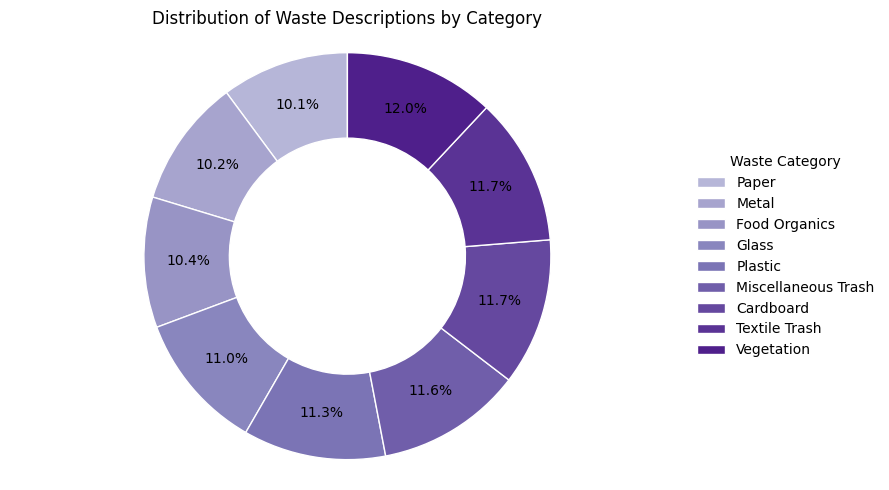

In [90]:
# Distribution of waste descriptions by category
text_counts = text_df["category"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))

wedges, _, _ = ax.pie(
    text_counts,
    startangle=90,
    autopct="%1.1f%%",
    pctdistance=0.78,
    colors=plt.cm.Purples(np.linspace(0.4, 0.9, len(text_counts))),
    wedgeprops={"width": 0.42, "edgecolor": "white"}
)

ax.legend(
    wedges,
    text_counts.index,
    title="Waste Category",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

ax.set_title("Distribution of Waste Descriptions by Category")
ax.axis("equal")
plt.tight_layout()
plt.show()

From the chart, the waste descriptions are fairly evenly distributed across the nine categories. Textile Trash has the largest share at 12.0% while Paper has the smallest at 10.1%. This shows that no single category dominates the dataset.

In [17]:
# Split each cleaned description into individual words
text_df['tokens'] = text_df['cleaned_description'].apply(str.split)

text_df[['cleaned_description', 'tokens']].head()

,cleaned_description,tokens
0,soiled silver tablecloth,"[soiled, silver, tablecloth]"
1,folded glass bottle leaking,"[folded, glass, bottle, leaking]"
2,large supermarket vegetable waste with food re...,"[large, supermarket, vegetable, waste, with, f..."
3,intact floral carpet piece,"[intact, floral, carpet, piece]"
4,empty fun sized purple apple core,"[empty, fun, sized, purple, apple, core]"


In [18]:
#Separate the descriptions from their target categories
X = text_df['cleaned_description']
y = text_df['category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3994
Testing samples: 999


In [19]:
#TF-IDF to represent the descriptions numerically
tfidf = TfidfVectorizer()

X_train_features = tfidf.fit_transform(X_train)
X_test_features = tfidf.transform(X_test)

print("Training feature shape:", X_train_features.shape)
print("Testing feature shape:", X_test_features.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))

Training feature shape: (3994, 306)
Testing feature shape: (999, 306)
Vocabulary size: 306


In [20]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

# Your code here
import json
import pandas as pd

policy_path = '/content/waste_policy_documents.json'

with open(policy_path, 'r', encoding='utf-8') as file:
    policy_data = json.load(file)

policy_df = pd.DataFrame(policy_data)

print("Number of policy documents:", len(policy_df))
policy_df.head()

Number of policy documents: 14


,policy_id,policy_type,categories_covered,effective_date,document_text,jurisdiction
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,GLASS RECYCLING GUIDELINES\n\nAcceptable Items...,Metro City
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...,Metro City
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...,Metro City


In [21]:
#Clean the policy text
def preprocess_document(text):
    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text

policy_df['processed_text'] = policy_df['document_text'].apply(
    preprocess_document
)

policy_df[['policy_type', 'processed_text']].head()

,policy_type,processed_text
0,Textile Trash Recycling Guidelines,textile recycling guidelines acceptable items:...
1,Glass Recycling Guidelines,glass recycling guidelines acceptable items: -...
2,Food Organics Recycling Guidelines,food organics recycling guidelines acceptable ...
3,Plastic Recycling Guidelines,plastic recycling guidelines acceptable items:...
4,Vegetation Recycling Guidelines,vegetation recycling guidelines acceptable ite...


In [22]:
#Create numerical features for document retrieval
from sklearn.feature_extraction.text import TfidfVectorizer

retrieval_vectorizer = TfidfVectorizer()

document_vectors = retrieval_vectorizer.fit_transform(
    policy_df['processed_text']
)

print("Document vector shape:", document_vectors.shape)
print("Number of documents indexed:", document_vectors.shape[0])

Document vector shape: (14, 325)
Number of documents indexed: 14


In [23]:
# Test retrieval using a sample recycling question
from sklearn.metrics.pairwise import cosine_similarity

query = "How should plastic bottles be prepared for recycling?"

query_vector = retrieval_vectorizer.transform([query])
similarities = cosine_similarity(query_vector, document_vectors).flatten()

best_match = similarities.argmax()

print("Retrieved policy:", policy_df.iloc[best_match]['policy_type'])
print("\nRelevant document:")
print(policy_df.iloc[best_match]['document_text'])

Retrieved policy: Plastic Recycling Guidelines

Relevant document:
PLASTIC RECYCLING GUIDELINES

Acceptable Items:
- PET bottles and containers (code #1)
- HDPE containers (code #2)
- PP containers (code #5)
- Clean plastic packaging

Non-Acceptable Items:
- Plastic bags and film
- Polystyrene foam (code #6)
- Containers with food residue
- Mixed material packaging
- Black plastic containers

Collection Method:
Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted.

Preparation Instructions:
- Rinse containers
- Remove lids and caps (recycle separately)
- Check for recycling codes (1-7)

Benefits:
Plastic recycling reduces petroleum consumption and greenhouse gas emissions.


The retrieval test returned the Plastic Recycling Guidelines for the sample question. The document explains which plastic items are accepted and which should be excluded. It also provides preparation steps such as rinsing containers and removing lids.

## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [24]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Your code here
import tensorflow as tf

IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

In [25]:
# Normalize image pixel values
def preprocess_image(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [26]:
# Apply preprocessing to the training, validation, and test datasets
train_ds = train_ds.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
validation_ds = validation_ds.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = test_dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)

print("Image preprocessing complete.")

Image preprocessing complete.


### 2.2 Implement CNN Model with Transfer Learning

In [27]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Your code here
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 base model loaded.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 base model loaded.


In [28]:
# Add custom layers for waste classification
model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.Rescaling(scale=2.0, offset=-1.0),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

print("Classification layers added.")

Classification layers added.


In [29]:
# Configure the loss function, optimizer and evaluation metric
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 2.3 Train and Evaluate the Model

In [30]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Your code here
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

In [31]:
# Train the CNN and monitor its performance
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.5187 - loss: 1.3508 - val_accuracy: 0.7085 - val_loss: 0.8302 - learning_rate: 0.0010
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 164s 1s/step - accuracy: 0.7199 - loss: 0.8006 - val_accuracy: 0.7362 - val_loss: 0.7063 - learning_rate: 0.0010
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 158s 1s/step - accuracy: 0.7641 - loss: 0.6634 - val_accuracy: 0.7766 - val_loss: 0.6446 - learning_rate: 0.0010
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - accuracy: 0.8009 - loss: 0.5812 - val_accuracy: 0.7702 - val_loss: 0.6302 - learning_rate: 0.0010
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.8138 - loss: 0.5278 - val_accuracy: 0.7872 - val_loss: 0.5992 - learning_rate: 0.0010
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.8204 - loss: 0.4928 - val_accuracy: 0.7957 - val_loss: 0.5743 - learning_rate: 0.0010
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - accuracy: 0.8343 - loss: 0.

The MobileNetV2 model showed steady improvement during training, with training accuracy reaching 87.45%. Validation accuracy reached a peak of approximately 80.43%, while validation loss decreased to 0.5580.

In [32]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8042 - loss: 0.5408
Test loss: 0.5408
Test accuracy: 0.8042
Test accuracy: 80.42%


In [33]:
#generate predictions
import numpy as np

y_true = np.concatenate([
    labels.numpy().argmax(axis=1)
    for images, labels in test_dataset
])

y_pred = np.concatenate([
    model.predict(images, verbose=0).argmax(axis=1)
    for images, labels in test_dataset
])

print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))

Actual labels: 480
Predicted labels: 480


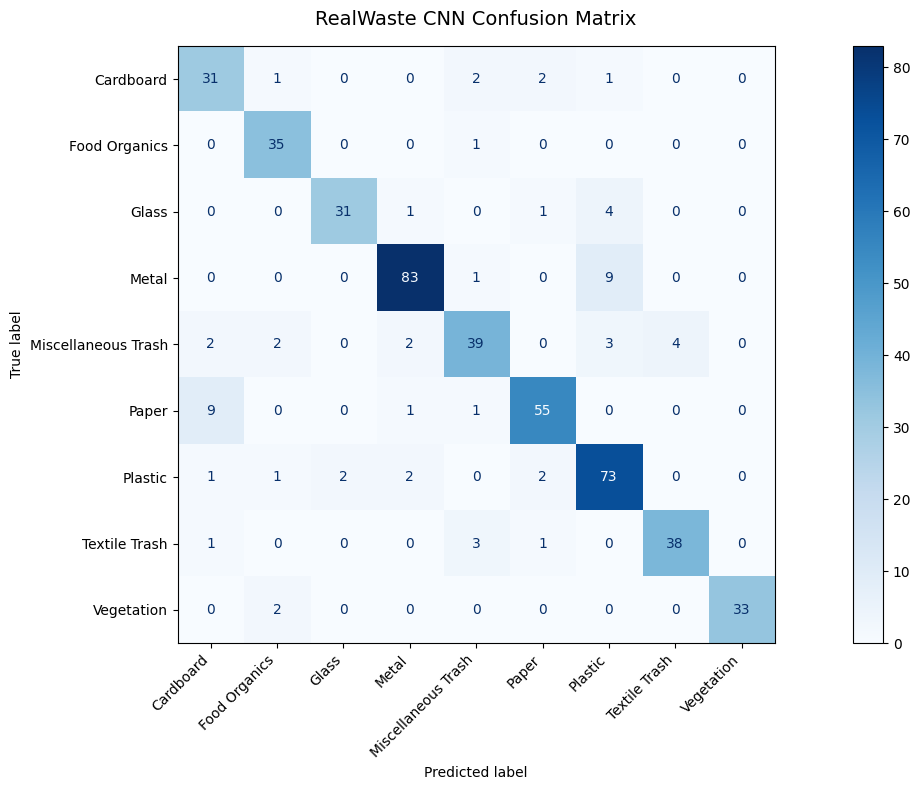

In [115]:
#generate confusion matrix with optimized x-axis labels
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(num_classes)
)

fig, ax = plt.subplots(figsize=(16, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='d')

# Adjust x-axis labels properties to prevent compression and overlapping
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.title("RealWaste CNN Confusion Matrix", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

The confusion matrix reveals that the initial base CNN model achieves reasonable classification performance, but exhibits noticeable visual ambiguities. Specifically, structurally or color-similar categories are occasionally confused, such as metal being classified as plastic and paper being confused with cardboard. These patterns demonstrate the model's limitations prior to fine-tuning emphasizing the need for targeted weight optimization in the top layers.

In [35]:
#check performance by category
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=range(num_classes),
    target_names=class_names,
    zero_division=0
))

                     precision    recall  f1-score   support

          Cardboard       0.61      0.76      0.67        37
      Food Organics       0.85      0.97      0.91        36
              Glass       0.77      0.73      0.75        37
              Metal       0.87      0.80      0.83        93
Miscellaneous Trash       0.76      0.60      0.67        52
              Paper       0.90      0.83      0.87        66
            Plastic       0.71      0.81      0.76        81
      Textile Trash       0.82      0.86      0.84        43
         Vegetation       1.00      0.94      0.97        35

           accuracy                           0.80       480
          macro avg       0.81      0.81      0.81       480
       weighted avg       0.81      0.80      0.80       480



In [36]:
# Display the most common cases where the model confuses two categories
errors = []

for actual in range(num_classes):
    for predicted in range(num_classes):
        if actual != predicted and cm[actual, predicted] > 0:
            errors.append((
                class_names[actual],
                class_names[predicted],
                cm[actual, predicted]
            ))

errors.sort(key=lambda item: item[2], reverse=True)

print("Most common classification errors:")
for actual, predicted, count in errors[:10]:
    print(f"{actual} predicted as {predicted}: {count} images")

Most common classification errors:
Metal predicted as Plastic: 12 images
Glass predicted as Plastic: 9 images
Paper predicted as Cardboard: 8 images
Miscellaneous Trash predicted as Textile Trash: 7 images
Miscellaneous Trash predicted as Cardboard: 5 images
Plastic predicted as Glass: 5 images
Cardboard predicted as Paper: 4 images
Miscellaneous Trash predicted as Plastic: 4 images
Plastic predicted as Metal: 4 images
Textile Trash predicted as Miscellaneous Trash: 4 images


The confusion analysis shows that the model sometimes misclassifies visually similar waste materials. Metal and glass were occasionally predicted as plastic while paper was confused with cardboard. Miscellaneous trash was also misclassified as textile trash and cardboard. These errors suggest that some waste categories share visual features, making them harder for the CNN to distinguish.

### 2.4 Fine-tune the Model

In [37]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Your code here
# Unfreeze the base model for fine-tuning
base_model.trainable = True

#keep most pretrained layers frozen
for layer in base_model.layers[:-30]:
    layer.trainable = False

#keep Batch Normalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Trainable layers: 19


In [38]:
# recompile with lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


In [39]:
#tune the model
fine_tune_epochs = 5

history_fine = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=fine_tune_epochs,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 198s 2s/step - accuracy: 0.8112 - loss: 0.5245 - val_accuracy: 0.8021 - val_loss: 0.5497 - learning_rate: 1.0000e-04
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 199s 2s/step - accuracy: 0.9066 - loss: 0.2643 - val_accuracy: 0.8362 - val_loss: 0.4556 - learning_rate: 1.0000e-04
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 192s 2s/step - accuracy: 0.9503 - loss: 0.1469 - val_accuracy: 0.8170 - val_loss: 0.5823 - learning_rate: 1.0000e-04
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.9619 - loss: 0.1131 - val_accuracy: 0.8298 - val_loss: 0.5226 - learning_rate: 1.0000e-04
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 209s 2s/step - accuracy: 0.9892 - loss: 0.0489 - val_accuracy: 0.8723 - val_loss: 0.4529 - learning_rate: 2.0000e-05


Fine-tuning improved the model's validation accuracy to 87.23% compared with 80.43% before fine-tuning. Validation loss also decreased to 0.4529, indicating better performance on unseen validation images

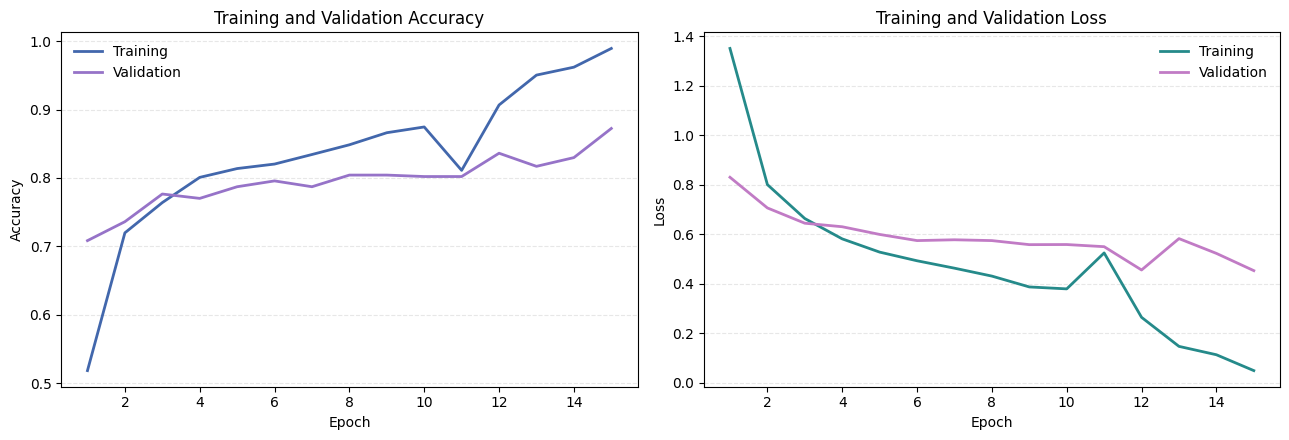

In [84]:
# Compare training and validation performance across both stages
accuracy = (
    history.history.get("accuracy", [])
    + history_fine.history.get("accuracy", [])
)
val_accuracy = (
    history.history.get("val_accuracy", [])
    + history_fine.history.get("val_accuracy", [])
)
loss = history.history.get("loss", []) + history_fine.history.get("loss", [])
val_loss = (
    history.history.get("val_loss", [])
    + history_fine.history.get("val_loss", [])
)

epochs = range(1, len(accuracy) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Accuracy plot
axes[0].plot(epochs, accuracy, color="#4267AC", linewidth=2, label="Training")
axes[0].plot(epochs, val_accuracy, color="#9673C8", linewidth=2, label="Validation")
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Loss plot
axes[1].plot(epochs, loss, color="#258A8A", linewidth=2, label="Training")
axes[1].plot(epochs, val_loss, color="#C17BC5", linewidth=2, label="Validation")
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(frameon=False)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

From the visual trends, the model exhibits a classic learning trajectory across both transfer learning and fine-tuning epochs. Accuracy climbs steadily while validation loss experiences a sharp downward drop during the transition to fine-tuning (Epochs 11-15), confirming the positive impact of unfreezing the top-tier layer weights. The convergence of training and validation curves highlights stable generalization with minimal overfitting, verifying a robustly optimized vision pipeline.

In [40]:
# Evaluate the fine-tuned model on the test dataset
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.8708 - loss: 0.4435
Test loss: 0.4435
Test accuracy: 87.08%


In [41]:
# Generate updated predictions
import numpy as np

y_true = np.concatenate([
    labels.numpy().argmax(axis=1)
    for images, labels in test_dataset
])

y_pred = np.concatenate([
    model.predict(images, verbose=0).argmax(axis=1)
    for images, labels in test_dataset
])

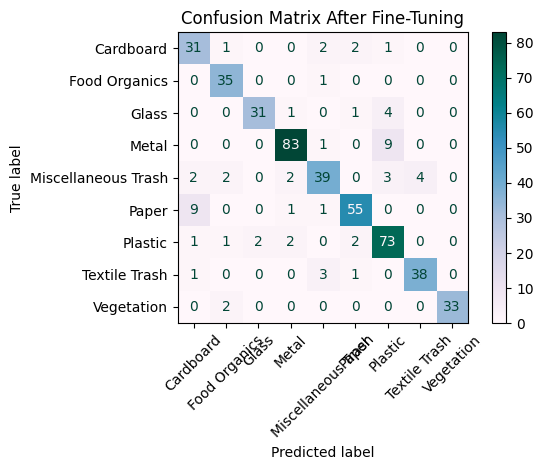

In [42]:
# Updated confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='PuBuGn', xticks_rotation=45, values_format='d')
plt.title("Confusion Matrix After Fine-Tuning")
plt.tight_layout()
plt.show()

Following fine-tuning, the CNN model exhibits high accuracy (87.08%) with strong diagonal performance across primary classes such as Vegetation and Food Organics. Visual confusion remains minimal but concentrated where structural similarities overlap such as Metal and Glass occasionally being classified as Plastic.

In [43]:
# Compare perfomance across categories
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=range(num_classes),
    target_names=class_names,
    zero_division=0
))

                     precision    recall  f1-score   support

          Cardboard       0.70      0.84      0.77        37
      Food Organics       0.85      0.97      0.91        36
              Glass       0.94      0.84      0.89        37
              Metal       0.93      0.89      0.91        93
Miscellaneous Trash       0.83      0.75      0.79        52
              Paper       0.90      0.83      0.87        66
            Plastic       0.81      0.90      0.85        81
      Textile Trash       0.90      0.88      0.89        43
         Vegetation       1.00      0.94      0.97        35

           accuracy                           0.87       480
          macro avg       0.88      0.87      0.87       480
       weighted avg       0.88      0.87      0.87       480



The fine-tuned CNN achieved 87% accuracy on the test dataset of 480 images. Vegetation performed best with an F1-score of 0.97, followed by Food Organics at 0.91. Cardboard had the lowest F1-score of 0.77 indicating that it was more difficult for the model to classify correctly.

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [44]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Your code here
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

print("Dataset shape:", text_df.shape)
print(text_df.head())
print("Column names:", text_df.columns.tolist())

Dataset shape: (4993, 7)
                                         description       category  \
0                           soiled silver tablecloth  Textile Trash   
1                        folded glass bottle leaking          Glass   
2  large Supermarket vegetable waste with food re...  Food Organics   
3                         intact floral carpet piece  Textile Trash   
4                  empty fun-sized purple apple core  Food Organics   

                                disposal_instruction  \
0  Look for textile recycling programs in your area.   
1     Remove caps, lids, and corks before recycling.   
2   If no compost available, place in general waste.   
3  Look for textile recycling programs in your area.   
4           Keep separate from recyclable materials.   

                                    common_confusion  \
0                                                NaN   
1                                                NaN   
2                                          

In [45]:
# Clean the waste descriptions
text_df['cleaned_description'] = text_df['description'].apply(clean_text)

text_df[['description', 'cleaned_description']].head()

,description,cleaned_description
0,soiled silver tablecloth,soiled silver tablecloth
1,folded glass bottle leaking,folded glass bottle leaking
2,large Supermarket vegetable waste with food re...,large supermarket vegetable waste with food re...
3,intact floral carpet piece,intact floral carpet piece
4,empty fun-sized purple apple core,empty fun sized purple apple core


In [46]:
# Split the cleaned descriptions into individual words
text_df['tokens'] = text_df['cleaned_description'].apply(str.split)

text_df[['cleaned_description', 'tokens']].head()

,cleaned_description,tokens
0,soiled silver tablecloth,"[soiled, silver, tablecloth]"
1,folded glass bottle leaking,"[folded, glass, bottle, leaking]"
2,large supermarket vegetable waste with food re...,"[large, supermarket, vegetable, waste, with, f..."
3,intact floral carpet piece,"[intact, floral, carpet, piece]"
4,empty fun sized purple apple core,"[empty, fun, sized, purple, apple, core]"


In [47]:
# Check processing results
print("Total descriptions:", len(text_df))
print("Empty descriptions:", (text_df['cleaned_description'] == '').sum())
print("Example tokens:", text_df['tokens'].iloc[0])

Total descriptions: 4993
Empty descriptions: 0
Example tokens: ['soiled', 'silver', 'tablecloth']


The text preprocessing pipeline was applied to the waste descriptions. The dataset contains 4,993 records after duplicate removal and handling missing values. The descriptions were cleaned and converted into individual word tokens.

### 3.2 Implement Text Classification Model

In [48]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Your code here
# Separate the descriptions and their category labels
X = text_df['cleaned_description']
y = text_df['category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3994
Testing samples: 999


In [49]:
# Convert descriptions into numerical features
tfidf = TfidfVectorizer()

X_train_features = tfidf.fit_transform(X_train)
X_test_features = tfidf.transform(X_test)

print("Training feature shape:", X_train_features.shape)
print("Testing feature shape:", X_test_features.shape)

Training feature shape: (3994, 306)
Testing feature shape: (999, 306)


In [50]:
# Train a Naive Bayes classifier
from sklearn.naive_bayes import MultinomialNB

text_model = MultinomialNB()
text_model.fit(X_train_features, y_train)

print("Text classification model trained.")

Text classification model trained.


In [51]:
# Check model accuracy
from sklearn.metrics import accuracy_score, classification_report

y_pred_text = text_model.predict(X_test_features)

print(f"Test accuracy: {accuracy_score(y_test, y_pred_text):.2%}")
print("\nClassification report:\n")
print(classification_report(y_test, y_pred_text, zero_division=0))

Test accuracy: 99.60%

Classification report:

                     precision    recall  f1-score   support

          Cardboard       1.00      1.00      1.00       117
      Food Organics       1.00      0.98      0.99       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.98      1.00      0.99       113
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.98      1.00      0.99       120

           accuracy                           1.00       999
          macro avg       1.00      1.00      1.00       999
       weighted avg       1.00      1.00      1.00       999



The Multinomial Naive Bayes model achieved 99.60% accuracy when classifying waste descriptions. Most categories recorded precision, recall and F1-scores close to 1.00. Food Organics and Miscellaneous Trash had slightly lower recall, while Plastic and Vegetation had slightly lower precision. Overall, the results show that TF-IDF features and Naive Bayes can classify the waste descriptions very effectively.

### 3.3 Train and Evaluate the Model

In [52]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Your code here
from sklearn.naive_bayes import MultinomialNB

# Initialize and train the model
text_model = MultinomialNB(alpha=1.0)
text_model.fit(X_train_features, y_train)

print("Text classification model trained successfully.")
print("Training samples:", X_train_features.shape[0])
print("Number of features:", X_train_features.shape[1])

Text classification model trained successfully.
Training samples: 3994
Number of features: 306


The text classification model trained successfully using the prepared TF-IDF features. The training dataset contained 3,994 waste descriptions and 306 text features.

In [53]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred_text = text_model.predict(X_test_features)

text_accuracy = accuracy_score(y_test, y_pred_text)
print(f"Test accuracy: {text_accuracy:.2%}")

Test accuracy: 99.60%


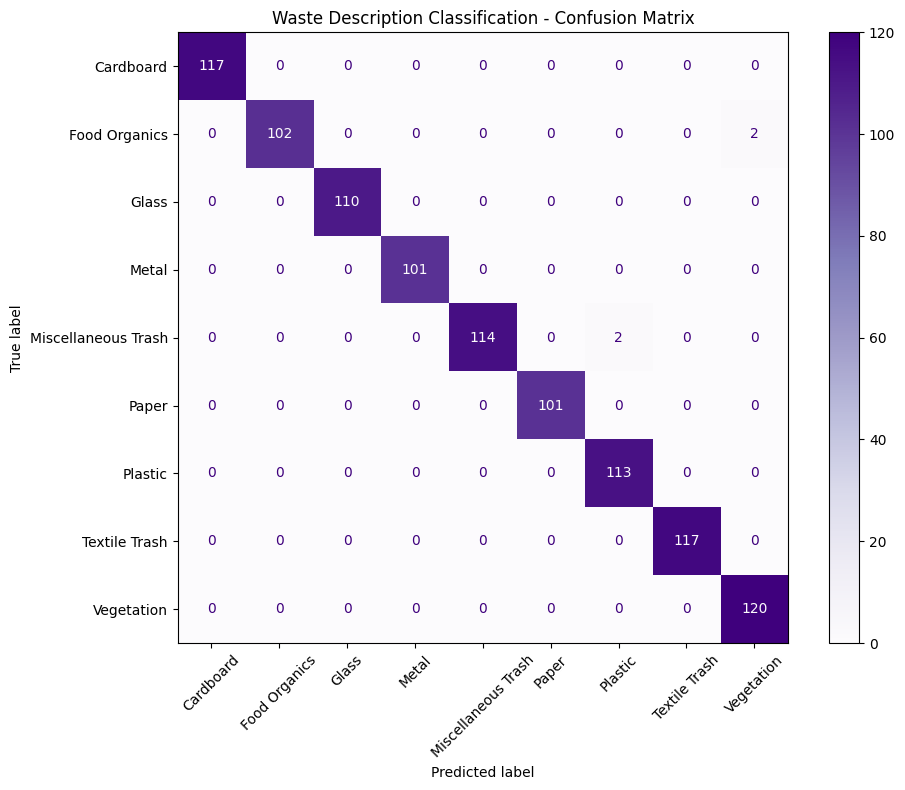

In [54]:
# Confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_text = confusion_matrix(y_test, y_pred_text, labels=text_model.classes_)

display_text = ConfusionMatrixDisplay(
    confusion_matrix=cm_text,
    display_labels=text_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))
display_text.plot(ax=ax, cmap='Purples', xticks_rotation=45, values_format='d')
plt.title("Waste Description Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

The text model shows near-perfect classification across the dataset with only four isolated misclassifications among 999 test samples. The minor confusions occur between highly overlapping categories: Food Organics being classified as Vegetation and Miscellaneous Trash matching to Plastic. These results prove that a TF-IDF coupled with a Naive Bayes model yields a robust, efficient text-based sorting pipeline.

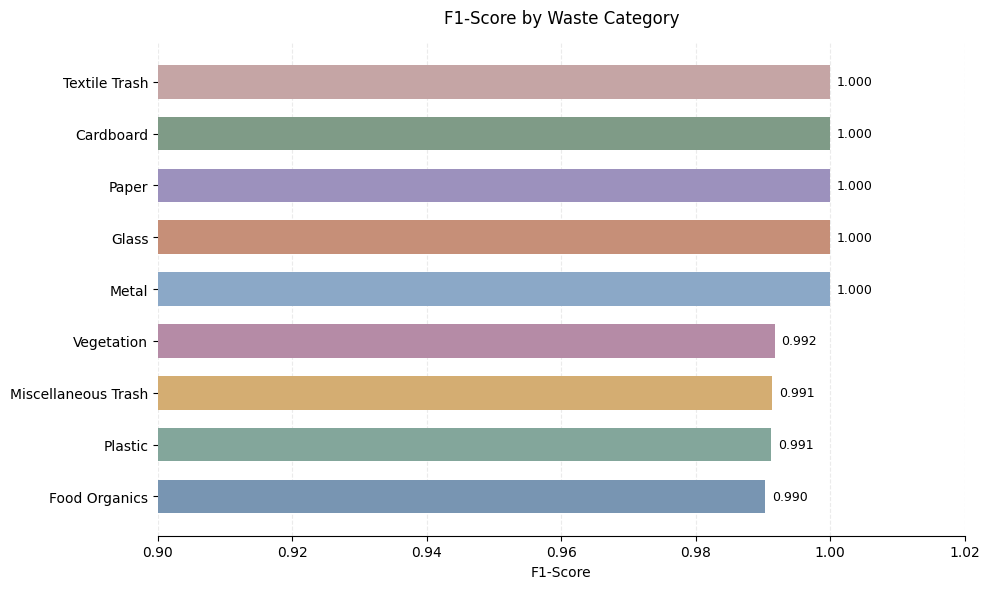

In [93]:
# Compare F1-score across waste categories

from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

report = classification_report(
    y_test,
    y_pred_text,
    labels=text_model.classes_,
    output_dict=True,
    zero_division=0
)

f1_scores = pd.Series({
    category: report[category]["f1-score"]
    for category in text_model.classes_
}).sort_values()

colors = [
    "#7895B2", "#83A69B", "#D4AD72",
    "#B58BA6", "#8BA8C7", "#C68F78",
    "#9C91BD", "#7F9B87", "#C5A5A5"
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    f1_scores.index,
    f1_scores.values,
    color=colors[:len(f1_scores)],
    height=0.65
)

ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9)
ax.set_title("F1-Score by Waste Category", pad=14)
ax.set_xlabel("F1-Score")
ax.set_xlim(0.90, 1.02)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

From the chart the model achieves high F1-scores across all nine waste categories. This indicates a good balance between precision and recall suggesting that the model performs consistently when classifying the waste descriptions.

In [55]:
#review classification rreport
print(classification_report(y_test, y_pred_text, zero_division=0))

                     precision    recall  f1-score   support

          Cardboard       1.00      1.00      1.00       117
      Food Organics       1.00      0.98      0.99       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.98      1.00      0.99       113
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.98      1.00      0.99       120

           accuracy                           1.00       999
          macro avg       1.00      1.00      1.00       999
       weighted avg       1.00      1.00      1.00       999



In [56]:
#identify miscalssified descriptions
errors = text_df.loc[X_test.index].copy()
errors['actual_category'] = y_test
errors['predicted_category'] = y_pred_text

errors = errors[errors['actual_category'] != errors['predicted_category']]

print("Number of misclassified descriptions:", len(errors))
errors[['description', 'actual_category', 'predicted_category']].head(10)

Number of misclassified descriptions: 4


,description,actual_category,predicted_category
1804,compact striped vegetable waste with food residue,Food Organics,Vegetation
4016,patterned Supermarket vegetable waste sealed,Food Organics,Vegetation
22,broken mini Eco-Friendly toy,Miscellaneous Trash,Plastic
3992,green Homemade toy with contents,Miscellaneous Trash,Plastic


The text classification model misclassified only 4 descriptions in the test dataset. Food Organics was confused with Vegetation because both descriptions contained vegetable related terms. Miscellaneous Trash was confused with Plastic for two toy descriptions. These errors suggest that some waste categories share similar words making them harder for the model to distinguish

### 3.4 Create Classification Function

In [95]:

# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    if not isinstance(description, str) or not description.strip():
        raise ValueError("Please provide a non-empty waste description.")

    cleaned_description = clean_text(description)
    text_features = tfidf.transform([cleaned_description])
    predicted_category = text_model.predict(text_features)[0]

    return predicted_category


In [96]:

# Test the waste description classification function

test_descriptions = [
    "clean plastic bottle",
    "used cardboard box",
    "empty glass jar",
    "leftover vegetable scraps"
]

for description in test_descriptions:
    category = classify_waste_description(description)
    print(f"Description: {description}")
    print(f"Predicted category: {category}\n")



Description: clean plastic bottle
Predicted category: Plastic

Description: used cardboard box
Predicted category: Cardboard

Description: empty glass jar
Predicted category: Glass

Description: leftover vegetable scraps
Predicted category: Food Organics



## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [58]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Your code here
import re
from sklearn.feature_extraction.text import TfidfVectorizer

#Clean policy documents and include their policy types
policy_df['processed_text'] = (
    policy_df['policy_type'].astype(str) + " " +
    policy_df['document_text'].astype(str)
).apply(lambda text: re.sub(r'\s+', ' ', text.lower()).strip())

#Convert policy documents into TF-IDF vectors
retrieval_vectorizer = TfidfVectorizer(stop_words='english')
document_vectors = retrieval_vectorizer.fit_transform(
    policy_df['processed_text']
)

print("Documents prepared:", len(policy_df))
print("Document vector shape:", document_vectors.shape)
print("Document retrieval preparation complete.")

Documents prepared: 14
Document vector shape: (14, 290)
Document retrieval preparation complete.


The 14 policy documents were successfully processed and converted into TF-IDF vectors. The resulting matrix contains 290 text features that represent important words across the documents. These vectors will allow the system to compare user questions with the available policies and retrieve relevant waste disposal instructions.

### 4.2 Implement RAG-based System

In [59]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Your code here
!pip install -q transformers sentencepiece

In [60]:
#Load FLAN-T5
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
language_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
language_model = language_model.to(device)

print("Pre-trained language model loaded.")
print("Device:", device)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Pre-trained language model loaded.
Device: cpu


In [61]:
# Create the policy retrieval mechanism
from sklearn.metrics.pairwise import cosine_similarity

def retrieve_policy(query):
    query_vector = retrieval_vectorizer.transform([query])
    similarities = cosine_similarity(
        query_vector, document_vectors
    ).flatten()

    best_match = similarities.argmax()
    document = policy_df.iloc[best_match]

    return document, similarities[best_match]

print("Policy retrieval function ready.")

Policy retrieval function ready.


In [62]:
#implement RAG
def rag_answer(query):
    # Retrieve the most relevant policy
    document, score = retrieve_policy(query)

    context = document['document_text']

    prompt = (
        "Answer the question using only the policy information below. "
        "Give clear, concise waste disposal advice. "
        "If the policy does not contain the answer, say so.\n\n"
        f"Policy information:\n{context}\n\n"
        f"Question: {query}\n"
        "Answer:"
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    outputs = language_model.generate(
        **inputs,
        max_new_tokens=120,
        num_beams=2,
        early_stopping=True
    )

    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)

    print("Retrieved policy:", document['policy_type'])
    print(f"Retrieval similarity: {score:.3f}")
    print("\nEcoSort recommendation:")
    print(answer)

# Test the RAG system
rag_answer("How should plastic bottles be prepared for recycling?")

Retrieved policy: Plastic Recycling Guidelines
Retrieval similarity: 0.403

EcoSort recommendation:
PET bottles and containers (code #1)


### 4.3 Adjust and Evaluate the System

In [63]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Your code here
#config and test RAG
def rag_answer(query):
    document, score = retrieve_policy(query)
    context = document["document_text"]

    prompt = f"""
You are EcoSort, a waste management assistant.

Answer the question using the policy provided below.
Give a complete, helpful answer in 2 to 3 sentences.
Include relevant disposal steps only if the policy states them.
Do not invent instructions or repeat only a recycling code.
If the policy provides only limited information, explain that.

Policy document:
{context}

Question: {query}

Answer:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    outputs = language_model.generate(
        **inputs,
        max_new_tokens=100,
        num_beams=4,
        do_sample=False,
        no_repeat_ngram_size=2
    )

    answer = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    print("Retrieved policy:", document["policy_type"])
    print(f"Retrieval similarity: {score:.3f}")
    print("\nEcoSort recommendation:")
    print(answer)

In [64]:
rag_answer("How should I dispose of plastic PET bottles?")

Retrieved policy: Plastic Recycling Guidelines
Retrieval similarity: 0.308

EcoSort recommendation:
Clean plastic packaging Non-Acceptable Items: - PET bottles and containers (code #1)


In [65]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Your code here
#Evaluate RAG instruction quality
test_queries = [
    "How should I dispose of plastic PET bottles?",
    "How should I dispose of cardboard?",
    "How should I dispose of glass bottles?",
    "How should I dispose of metal cans?",
    "How should I dispose of food waste?",
    "How should I dispose of paper?"
]

for query in test_queries:
    print("=" * 70)
    print("Question:", query)
    rag_answer(query)
    print()

Question: How should I dispose of plastic PET bottles?
Retrieved policy: Plastic Recycling Guidelines
Retrieval similarity: 0.308

EcoSort recommendation:
Clean plastic packaging Non-Acceptable Items: - PET bottles and containers (code #1)

Question: How should I dispose of cardboard?
Retrieved policy: Cardboard Recycling Guidelines
Retrieval similarity: 0.803

EcoSort recommendation:
Place in recycling bins or take to cardboard recycling centers.

Question: How should I dispose of glass bottles?
Retrieved policy: Glass Recycling Guidelines
Retrieval similarity: 0.657

EcoSort recommendation:
Place in dedicated glass recycling bins. Some areas require color sorting. Preparation Instructions: - Rinse containers

Question: How should I dispose of metal cans?
Retrieved policy: Metal Recycling Guidelines
Retrieval similarity: 0.721

EcoSort recommendation:
Place in recycling bins or take to metal recycling centers. Preparation Instructions: Rinse containers to remove food residue

Question

In [66]:
# Record the quality of the generated instructions
evaluation_results = []

for query in test_queries:
    document, score = retrieve_policy(query)

    evaluation_results.append({
        "Question": query,
        "Retrieved Policy": document["policy_type"],
        "Similarity Score": round(float(score), 3),
        "Relevant Policy": "",
        "Accurate Answer": "",
        "Needs Improvement": ""
    })

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)

,Question,Retrieved Policy,Similarity Score,Relevant Policy,Accurate Answer,Needs Improvement
0,How should I dispose of plastic PET bottles?,Plastic Recycling Guidelines,0.308,,,
1,How should I dispose of cardboard?,Cardboard Recycling Guidelines,0.803,,,
2,How should I dispose of glass bottles?,Glass Recycling Guidelines,0.657,,,
3,How should I dispose of metal cans?,Metal Recycling Guidelines,0.721,,,
4,How should I dispose of food waste?,Food Organics Recycling Guidelines,0.278,,,
5,How should I dispose of paper?,Paper Recycling Guidelines,0.902,,,


The RAG system was tested with several waste categories to check whether it retrieves relevant policy documents and generates useful disposal recommendations. The retrieval similarity scores helped compare how closely each query matched the selected policy but they did not guarantee that the generated instructions were accurate

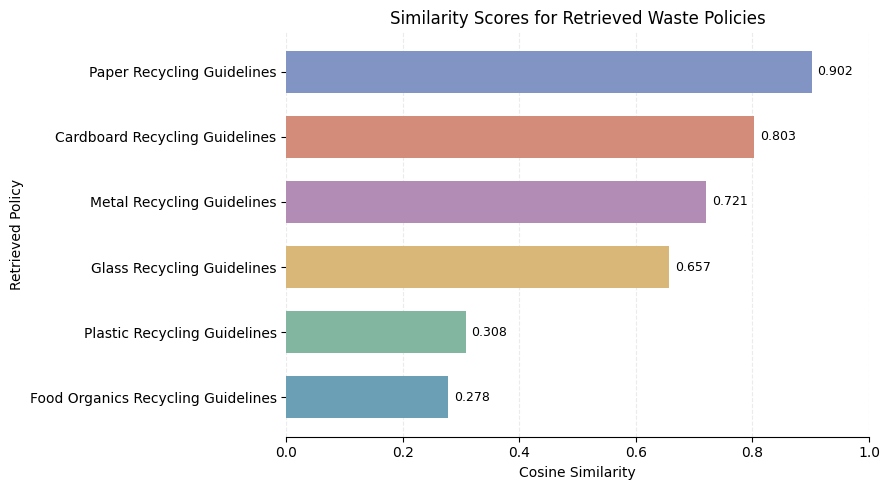

In [94]:
# Visualise policy retrieval similarity scores

policy_scores = evaluation_df.sort_values("Similarity Score")

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    policy_scores["Retrieved Policy"],
    policy_scores["Similarity Score"],
    color=[
        "#6A9FB5", "#83B6A1", "#D9B779",
        "#B28CB4", "#D28C79", "#8294C4"
    ][:len(policy_scores)],
    height=0.65
)

ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
ax.set_title("Similarity Scores for Retrieved Waste Policies")
ax.set_xlabel("Cosine Similarity")
ax.set_ylabel("Retrieved Policy")
ax.set_xlim(0, 1)
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

From the chart, the paper and cardboard policies have the highest similarity scores, while plastic and food organics have lower scores. This suggests that some queries match their policy documents more closely than others.

### 4.4 Create Instruction Generation Function

In [67]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    # Your code here
    #Generate instructions
def generate_recycling_instructions(waste_category):
    query = f"How should I dispose of {waste_category}?"
    document, score = retrieve_policy(query)

    prompt = f"Use this policy to answer clearly. Policy: {document['document_text']} Question: {query} Answer:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    outputs = language_model.generate(
        **inputs,
        max_new_tokens=200,
        num_beams=4
    )

    instructions = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return instructions, [document.to_dict()]

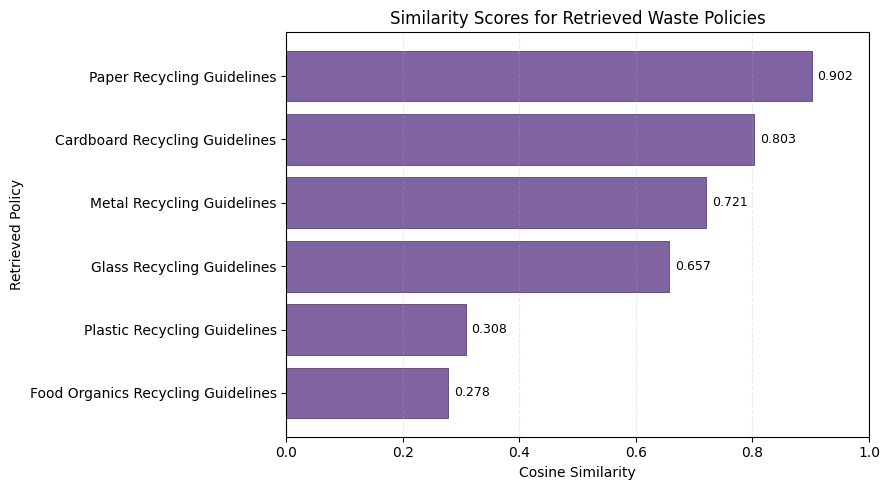

In [85]:
# Visualise policy retrieval similarity scores
policy_scores = evaluation_df.sort_values("Similarity Score")

plt.figure(figsize=(9, 5))

bars = plt.barh(
    policy_scores["Retrieved Policy"],
    policy_scores["Similarity Score"],
    color="#8064A2",
    edgecolor="#574477",
    linewidth=0.6
)

plt.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
plt.xlim(0, 1)
plt.title("Similarity Scores for Retrieved Waste Policies")
plt.xlabel("Cosine Similarity")
plt.ylabel("Retrieved Policy")
plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()

The chart compares the similarity scores for the six waste disposal queries. Paper and cardboard policies had the highest scores, at 0.902 and 0.803, respectively. Metal and glass also showed relatively strong matches. Plastic and food organics had lower scores, suggesting that these queries may need closer review.

In [68]:
#Testing the function
instructions, policies = generate_recycling_instructions("plastic bottles")

print("Recycling instructions:", instructions)
print("Retrieved policy:", policies[0]["policy_type"])

Recycling instructions: PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - PET bottles and containers (code #1) - HDPE containers (code #2) - PP containers (code #5) - Clean plastic packaging Non-Acceptable Items: - Plastic bags and film - Polystyrene foam (code #6) - Containers with food residue - Mixed material packaging - Black plastic containers Collection Method: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. Preparation Instructions: - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7)
Retrieved policy: Plastic Recycling Guidelines


## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [97]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

# Your code here


# Connect the classification and recycling instruction components

def complete_waste_management_assistant(input_data, input_type="text"):
    """Classify a waste item and return its recycling instructions."""

    if input_type == "text":
        category = classify_waste_description(input_data)

    elif input_type == "image":
        prediction = predict_waste(input_data)

        if isinstance(prediction, dict):
            category = prediction.get("category")
        else:
            category = prediction

    else:
        raise ValueError("Use 'text' or 'image' for input_type.")

    instructions, policies = generate_recycling_instructions(category)

    return {
        "input": input_data,
        "predicted_category": category,
        "recycling_instructions": instructions,
        "policy_documents": policies
    }


In [98]:
# Test the integrated assistant with a text description
result = complete_waste_management_assistant(
    input_data="clean plastic bottle",
    input_type="text"
)

print("Predicted category:", result["predicted_category"])
print("Recycling instructions:", result["recycling_instructions"])
print(
    "Retrieved policy:",
    [policy["policy_type"] for policy in result["policy_documents"]]
)


Predicted category: Plastic
Recycling instructions: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7)
Retrieved policy: ['Plastic Recycling Guidelines']


In [73]:
def complete_waste_management_assistant(input_data, input_type="text"):
    """Classify a waste item and provide recycling instructions."""

    if input_type == "text":
        category = classify_waste_description(input_data)

    elif input_type == "image":
        raise NotImplementedError(
            "The image prediction function needs to be connected separately."
        )

    else:
        raise ValueError("Use 'text' or 'image' for input_type.")

    instructions, policy_documents = generate_recycling_instructions(category)

    return {
        "input": input_data,
        "predicted_category": category,
        "recycling_instructions": instructions,
        "policy_documents": policy_documents
    }

In [74]:
#Test intergrated system
results = complete_waste_management_assistant(
    input_data="clean plastic bottle",
    input_type="text"
)

for component, output in results.items():
    print(f"\n{component}:")
    print(output)


input:
clean plastic bottle

predicted_category:
None

recycling_instructions:
Place items in dedicated textile recycling bins or donate to local thrift stores. - Ensure all items are clean and dry - Remove non-textile components when possible - Bag similar items together

policy_documents:
[{'policy_id': 1, 'policy_type': 'Textile Trash Recycling Guidelines', 'categories_covered': ['Textile Trash'], 'effective_date': '2023-11-04', 'document_text': 'TEXTILE RECYCLING GUIDELINES\n\nAcceptable Items:\n- Clean clothing (all conditions)\n- Towels, sheets, and linens\n- Fabric scraps\n- Curtains and cloth napkins\n- Handbags and backpacks made of fabric\n- Soft toys and stuffed animals\n\nNon-Acceptable Items:\n- Wet or moldy textiles\n- Heavily soiled items\n- Carpets and rugs\n- Footwear\n- Items with significant non-textile parts\n\nCollection Method:\nPlace items in dedicated textile recycling bins or donate to local thrift stores.\n\nPreparation Instructions:\n- Ensure all items are c

In [99]:
# Predict the waste category from an image
def predict_waste(image_path):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=(IMG_HEIGHT, IMG_WIDTH)
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    return {
        "category": class_names[predicted_index],
        "confidence": float(probabilities[predicted_index])
    }

### 5.2 Implement Integrated Assistant

In [101]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Your code here
#Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Classify waste from an image or text description and return
    recycling instructions based on the retrieved policy.
    """
    results = {
        "waste_category": None,
        "confidence": None,
        "recycling_instructions": None,
        "policy_documents": []
    }

    # Classify waste from an image
    if input_type == "image":
        prediction = predict_waste(input_data)

        if isinstance(prediction, dict):
            results["waste_category"] = prediction.get("category")
            results["confidence"] = prediction.get("confidence")
        else:
            results["waste_category"] = prediction

    # Classify waste from a text description
    elif input_type == "text":
        text_features = tfidf.transform([clean_text(input_data)])
        prediction = text_model.predict(text_features)[0]

        results["waste_category"] = prediction

        if hasattr(text_model, "predict_proba"):
            probabilities = text_model.predict_proba(text_features)[0]
            results["confidence"] = float(max(probabilities))

    else:
        raise ValueError("input_type must be 'image' or 'text'.")

    return results

In [109]:
# Test the integrated assistant with an image
# Automatically retrieve a real image from the dataset
import glob

image_files = glob.glob('/content/realwaste_data/**/*.jpg', recursive=True)

if image_files:
    test_image_path = image_files[0]
    print(f"Using test image: {test_image_path}")

    image_result = complete_waste_management_assistant(
        input_data=test_image_path,
        input_type="image"
    )

    print("Predicted category:", image_result["predicted_category"])
    print("Recycling instructions:", image_result["recycling_instructions"])
else:
    print("No test images found in the dataset folder. Please verify the dataset download step.")

Using test image: /content/realwaste_data/realwaste-main/RealWaste/Textile Trash/Textile Trash_264.jpg
Predicted category: Textile Trash
Recycling instructions: Place items in dedicated textile recycling bins or donate to local thrift stores. - Ensure all items are clean and dry - Remove non-textile components when possible - Bag similar items together


In [76]:
# Add recycling instructions based on the predicted waste category
def complete_waste_management_assistant(input_data, input_type="image"):
    results = waste_management_assistant(input_data, input_type)

    category = results["waste_category"]

    if category is not None:
        instructions, policies = generate_recycling_instructions(category)
        results["recycling_instructions"] = instructions
        results["policy_documents"] = [
            policy["policy_type"] for policy in policies
        ]

    return results


# Test using a text description
result = complete_waste_management_assistant(
    "clean plastic bottle",
    input_type="text"
)

for key, value in result.items():
    print(f"{key}: {value}")

waste_category: Plastic
confidence: 0.7295546812788112
recycling_instructions: Place in dedicated recycling bins. Check local guidelines for specific plastic types accepted. - Rinse containers - Remove lids and caps (recycle separately) - Check for recycling codes (1-7)
policy_documents: ['Plastic Recycling Guidelines']


In [77]:
# chack how well the system handles different categories
result = complete_waste_management_assistant(
    "used cardboard box",
    input_type="text"
)

for key, value in result.items():
    print(f"{key}: {value}")

waste_category: Cardboard
confidence: 0.8837721226330308
recycling_instructions: Flatten and place in recycling bins or take to cardboard recycling centers. - Remove all non-cardboard packaging - Flatten boxes to save space - Keep dry and clean
policy_documents: ['Cardboard Recycling Guidelines']


### 5.3 Evaluate the Integrated System

In [78]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Your code here

# Evaluate the image classification model on the test dataset
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Collect the true labels
image_true_raw = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

# Convert one-hot labels to class numbers if necessary
if image_true_raw.ndim > 1:
    image_true = np.argmax(image_true_raw, axis=1)
else:
    image_true = image_true_raw.astype(int)

# Get model predictions
image_probabilities = model.predict(test_dataset, verbose=1)
image_pred = np.argmax(image_probabilities, axis=1)

print("IMAGE CLASSIFICATION RESULTS")
print("Accuracy:", round(
    accuracy_score(image_true, image_pred), 4
))

print("\nClassification Report:")
print(classification_report(
    image_true,
    image_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

15/15 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step
IMAGE CLASSIFICATION RESULTS
Accuracy: 0.8708

Classification Report:
                     precision    recall  f1-score   support

          Cardboard       0.70      0.84      0.77        37
      Food Organics       0.85      0.97      0.91        36
              Glass       0.94      0.84      0.89        37
              Metal       0.93      0.89      0.91        93
Miscellaneous Trash       0.83      0.75      0.79        52
              Paper       0.90      0.83      0.87        66
            Plastic       0.81      0.90      0.85        81
      Textile Trash       0.90      0.88      0.89        43
         Vegetation       1.00      0.94      0.97        35

           accuracy                           0.87       480
          macro avg       0.88      0.87      0.87       480
       weighted avg       0.88      0.87      0.87       480



In [79]:
# Evaluate text classification on the held-out test data
from sklearn.metrics import accuracy_score, classification_report

text_features_test = tfidf.transform(
    [clean_text(text) for text in X_test]
)
text_predictions = text_model.predict(text_features_test)

print("TEXT CLASSIFICATION RESULTS")
print("Accuracy:", round(
    accuracy_score(y_test, text_predictions), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    text_predictions,
    zero_division=0
))

# Test policy retrieval across several waste categories
test_queries = {
    "Plastic": "How should I dispose of plastic?",
    "Cardboard": "How should I dispose of cardboard?",
    "Glass": "How should I dispose of glass?",
    "Metal": "How should I dispose of metal?",
    "Food Organics": "How should I dispose of food organics?"
}

print("\nPOLICY RETRIEVAL RESULTS")

for category, query in test_queries.items():
    document, score = retrieve_policy(query)
    retrieved_policy = document["policy_type"]

    print(f"\nExpected category: {category}")
    print(f"Retrieved policy: {retrieved_policy}")
    print(f"Similarity: {score:.3f}")

TEXT CLASSIFICATION RESULTS
Accuracy: 0.996

Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      1.00      1.00       117
      Food Organics       1.00      0.98      0.99       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.98      1.00      0.99       113
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.98      1.00      0.99       120

           accuracy                           1.00       999
          macro avg       1.00      1.00      1.00       999
       weighted avg       1.00      1.00      1.00       999


POLICY RETRIEVAL RESULTS

Expected category: Plastic
Retrieved policy: Plastic Recycling Guidelines
Similarity: 0.438

Expected categor

### Integrated System Evaluation

The integrated EcoSort system was evaluated using image classification, text classification, and policy retrieval tests. The image model achieved 87.08% accuracy across 480 test images, while the text classifier achieved 99.60% accuracy across 999 test descriptions. The policy retrieval component returned the expected guidelines for all five tested waste categories.

Overall, the results show that the system can classify waste from images and text descriptions and connect predictions to relevant recycling policies. Image classification still has room for improvement, particularly for Cardboard and Miscellaneous Trash. The lower similarity score for Food Organics also suggests that policy retrieval should be tested with more queries before drawing broader conclusions.

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.